In [1]:
import sys
print(sys.executable)

c:\Users\CSMLAB-I\Desktop\JobLens\venv\Scripts\python.exe


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

df = pd.read_csv("../data/cleaned/jobs_clean.csv")
print(df.shape)
df.head(3)

(1500, 26)


,job_id,job_title,job_category,experience_level,years_of_experience,education_required,annual_salary_usd,salary_min_usd,salary_max_usd,city,...,demand_score,demand_growth_yoy_pct,benefits_score_10,posting_year,posting_month,is_senior,is_remote_friendly,is_llm_role,salary_tier,salary_outside_range
0,AIJOB0001,AI Agent Developer,AI Engineering,Senior (6-9 yrs),7,Master's,239000.0,155000,290000,Boston,...,96,16.9,6.8,2026,3,1,0,1,Senior ($200-300k),False
1,AIJOB0002,Prompt Engineer,AI Engineering,Senior (6-9 yrs),2,Bachelor's,166000.0,90000,200000,London,...,82,11.6,6.2,2026,1,1,1,1,Upper-Mid ($150-200k),False
2,AIJOB0003,LLM Engineer,AI Engineering,Senior (6-9 yrs),4,Associate's,360000.0,160000,300000,Seattle,...,98,42.7,7.7,2026,1,1,1,1,Elite (>$300k),True


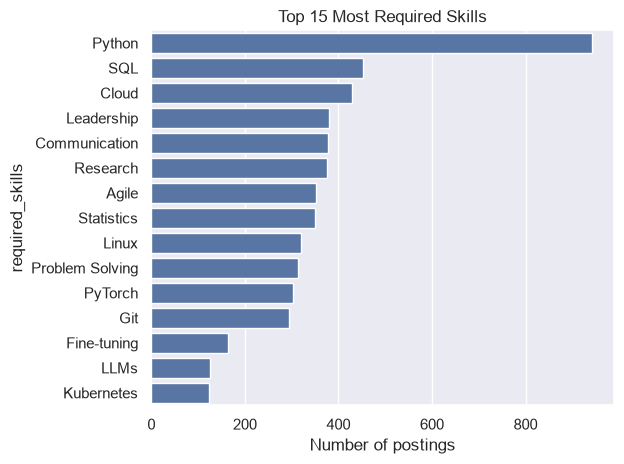

required_skills
Python             942
SQL                452
Cloud              429
Leadership         380
Communication      378
Research           376
Agile              351
Statistics         350
Linux              320
Problem Solving    314
PyTorch            302
Git                295
Fine-tuning        164
LLMs               125
Kubernetes         123
Name: count, dtype: int64

In [3]:
skills = df["required_skills"].str.split("|").explode().str.strip()
top = skills.value_counts().head(15)
sns.barplot(x=top.values, y=top.index)
plt.title("Top 15 Most Required Skills")
plt.xlabel("Number of postings")
plt.tight_layout()
plt.savefig("../reports/top_skills.png", dpi=150)
plt.show()
top

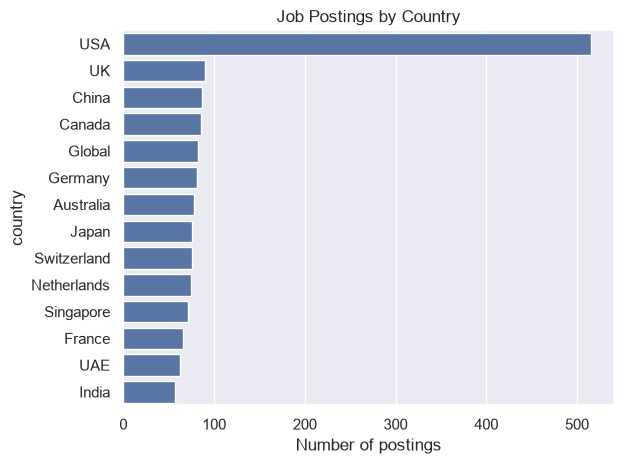

country
USA            515
UK              90
China           87
Canada          85
Global          82
Germany         81
Australia       78
Japan           76
Switzerland     76
Netherlands     74
Singapore       71
France          66
UAE             62
India           57
Name: count, dtype: int64

In [4]:
c = df["country"].value_counts()
sns.barplot(x=c.values, y=c.index)
plt.title("Job Postings by Country")
plt.xlabel("Number of postings")
plt.tight_layout()
plt.savefig("../reports/postings_by_country.png", dpi=150)
plt.show()
c

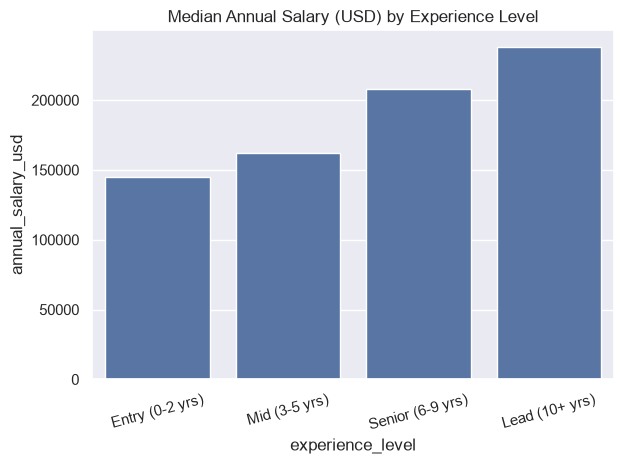

experience_level
Entry (0-2 yrs)     145000.0
Mid (3-5 yrs)       162000.0
Senior (6-9 yrs)    208000.0
Lead (10+ yrs)      238000.0
Name: annual_salary_usd, dtype: float64

In [5]:
order = ["Entry (0-2 yrs)", "Mid (3-5 yrs)", "Senior (6-9 yrs)", "Lead (10+ yrs)"]
sns.barplot(data=df, x="experience_level", y="annual_salary_usd",
            order=order, estimator="median", errorbar=None)
plt.title("Median Annual Salary (USD) by Experience Level")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("../reports/salary_by_experience.png", dpi=150)
plt.show()
df.groupby("experience_level")["annual_salary_usd"].median().reindex(order)

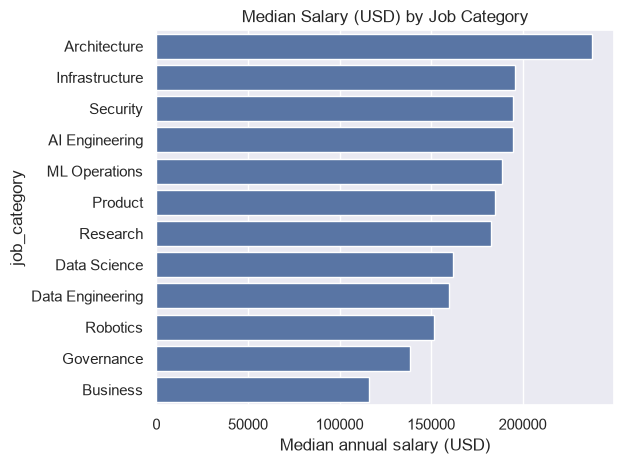

job_category
Architecture        238000.0
Infrastructure      196000.0
Security            194500.0
AI Engineering      194500.0
ML Operations       189000.0
Product             185000.0
Research            183000.0
Data Science        162000.0
Data Engineering    160000.0
Robotics            151500.0
Governance          138500.0
Business            116000.0
Name: annual_salary_usd, dtype: float64

In [6]:
med = df.groupby("job_category")["annual_salary_usd"].median().sort_values(ascending=False)
sns.barplot(x=med.values, y=med.index)
plt.title("Median Salary (USD) by Job Category")
plt.xlabel("Median annual salary (USD)")
plt.tight_layout()
plt.savefig("../reports/salary_by_category.png", dpi=150)
plt.show()
med

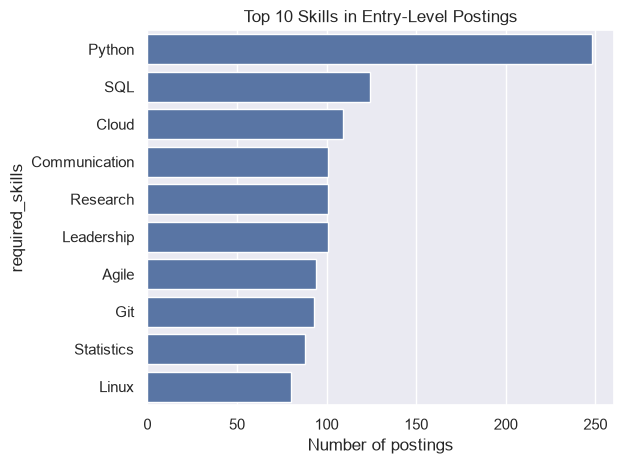

required_skills
Python           248
SQL              124
Cloud            109
Communication    101
Research         101
Leadership       101
Agile             94
Git               93
Statistics        88
Linux             80
Name: count, dtype: int64

In [7]:
entry = df[df["experience_level"] == "Entry (0-2 yrs)"]
e_skills = (entry["required_skills"].str.split("|").explode()
            .str.strip().value_counts().head(10))
sns.barplot(x=e_skills.values, y=e_skills.index)
plt.title("Top 10 Skills in Entry-Level Postings")
plt.xlabel("Number of postings")
plt.tight_layout()
plt.savefig("../reports/entry_level_skills.png", dpi=150)
plt.show()
e_skills

In [8]:
india = df[df["country"] == "India"]
print("India postings:", len(india))
print("Median salary, India:", india["annual_salary_usd"].median())
print("Median salary, all countries:", df["annual_salary_usd"].median())
print()
print(india["job_category"].value_counts())

India postings: 57
Median salary, India: 140000.0
Median salary, all countries: 180000.0

job_category
AI Engineering      25
Infrastructure       7
Data Engineering     4
Data Science         3
Governance           3
Security             3
Research             3
Product              3
Business             2
Robotics             2
Architecture         1
ML Operations        1
Name: count, dtype: int64


In [9]:
print("Median salary, all rows:", df["annual_salary_usd"].median())
print("Median salary, without flagged rows:",
      df[~df["salary_outside_range"]]["annual_salary_usd"].median())
      
print("Flagged rows:", int(df["salary_outside_range"].sum()))

Median salary, all rows: 180000.0
Median salary, without flagged rows: 161000.0
Flagged rows: 288
